# E3 — LSTM, GRU and baselines for image sequences

LSTM and GRU classify image sequences, with the MLP and CNN from E1 as baselines. AI assistance is disclosed in [AI_USE_REPORT.md](../AI_USE_REPORT.md).

## Experimental protocol

Four recurrent configurations use 30 epochs and seeds 42, 43 and 44, with the same split and preprocessing as E1.

In [1]:
from pathlib import Path
import subprocess
import sys

colab_root = Path("/content/CO5085-deep-learning")
roots = (Path.cwd(), *Path.cwd().parents, colab_root)
ROOT = next(
    (path for path in roots if (path / "configs/experiments.json").is_file()), None
)
if ROOT is None and "google.colab" in sys.modules:
    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "https://github.com/dathuynh1108/CO5085-deep-learning.git",
            str(colab_root),
        ],
        check=True,
    )
    ROOT = colab_root
if ROOT is None:
    raise FileNotFoundError(
        "Open the notebook from the CO5085-deep-learning directory."
    )
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image
from IPython.display import display

from common.config import get_experiment
from common.config import load_experiments
from common.data import CLASS_NAMES
from common.data import prepare_data
from common.engine import train
from common.evaluation import evaluate_run
from common.factory import build_model
from common.factory import parameter_count
from common.runtime import atomic_csv
from common.runtime import atomic_json
from common.runtime import choose_device
from common.runtime import environment_info
from common.runtime import seed_everything
from common.tokenization import image_sequence
from exercise_notebook import flag
from exercise_notebook import read_json
from exercise_notebook import setting
from exercise_notebook import show_comparison
from exercise_notebook import show_figure
from exercise_notebook import show_results
from exercise_notebook import verified_training_status

EXERCISE = "E3"

In [3]:
SEEDS = tuple(int(value) for value in setting("SEEDS", "42,43,44").split(","))
MODELS = setting("MODELS")
EPOCHS = int(setting("EPOCHS")) if setting("EPOCHS") else None
DEVICE = setting("DEVICE", "auto")
WORKERS = int(setting("WORKERS", "0"))
DATA_ROOT = (ROOT / setting("DATA_ROOT", "data")).resolve()
OUTPUT_ROOT = (ROOT / setting("OUTPUT_ROOT", "runs/notebooks/exercises")).resolve()
RESUME = flag("RESUME")
DETERMINISTIC = flag("DETERMINISTIC")
DOWNLOAD = flag("DOWNLOAD", default=True)
CONFIRM_TEST = flag("CONFIRM_TEST")

In [4]:
if (
    not SEEDS
    or len(set(SEEDS)) != len(SEEDS)
    or any(not 0 <= seed < 2**32 for seed in SEEDS)
):
    raise ValueError("SEEDS must contain distinct seeds in [0, 2**32).")
SEEDS = tuple(sorted(SEEDS))
if EPOCHS is not None and OUTPUT_ROOT == (ROOT / "runs/notebooks/exercises").resolve():
    raise ValueError(
        "Overriding EPOCHS requires a separate OUTPUT_ROOT for the short run."
    )
if OUTPUT_ROOT.is_relative_to((ROOT / "runs" / "exercises").resolve()):
    raise ValueError(
        "Choose an OUTPUT_ROOT outside the historical runs/exercises directory."
    )
if WORKERS < 0:
    raise ValueError("WORKERS must be a non-negative integer.")
if CONFIRM_TEST and EPOCHS is not None:
    raise ValueError("Runs with an EPOCHS override may only use validation evaluation.")
device = choose_device(DEVICE)

In [5]:
presets = load_experiments()
allowed = {
    row.id for row in presets if row.exercise == EXERCISE and row.group == "required"
}
allowed.update({"e1_mlp", "e1_cnn"})
selected = (
    tuple(value.strip() for value in MODELS.split(","))
    if MODELS
    else tuple(row.id for row in presets if row.id in allowed)
)
if len(set(selected)) != len(selected) or set(selected) - allowed:
    raise ValueError(f"MODELS must contain distinct IDs from: {sorted(allowed)}")
configs = [get_experiment(identifier, epochs=EPOCHS) for identifier in selected]
display(
    {
        "device": str(device),
        "seed": SEEDS,
        "worker": WORKERS,
        "output_root": str(OUTPUT_ROOT),
    }
)
display(
    [
        {
            key: config.to_dict()[key]
            for key in (
                "id",
                "epochs",
                "batch_size",
                "lr",
                "tokenizer",
                "backend",
                "group",
            )
        }
        for config in configs
    ]
)

{'device': 'cuda',
 'seed': (42, 43, 44),
 'worker': 4,
 'output_root': '/workspace/co5085/runs/notebooks/exercises'}

[{'id': 'e1_mlp',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'rows',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e1_cnn',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'rows',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e3_lstm_rows',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'rows',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e3_gru_rows',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'rows',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e3_lstm_patches',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'patches',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e3_gru_patches',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.001,
  'tokenizer': 'patches',
  'backend': 'manual',
  'group': 'required'}]

## Fashion-MNIST data exploration

The stratified split contains 54,000 training and 6,000 validation images; normalization uses training statistics, and 10,000 separate test images are used for evaluation.

In [6]:
split_seeds = {config.split_seed for config in configs}
if len(split_seeds) != 1:
    raise ValueError("Comparisons require the same data split.")
train_set, validation_set, dataset = prepare_data(
    DATA_ROOT, split_seeds.pop(), DOWNLOAD
)
train_counts = np.bincount(
    train_set.labels.numpy()[train_set.indices], minlength=len(CLASS_NAMES)
)
validation_counts = np.bincount(
    validation_set.labels.numpy()[validation_set.indices], minlength=len(CLASS_NAMES)
)
display(
    {
        key: dataset[key]
        for key in ("n_train", "n_validation", "mean", "std", "fingerprint")
    }
)

{'n_train': 54000,
 'n_validation': 6000,
 'mean': 0.2858728124583167,
 'std': 0.3528899747734446,
 'fingerprint': 'd4c63c5dac60102d9ae0cd935311a9eac958b8a81b8577c047e3c2b0056dc50e'}

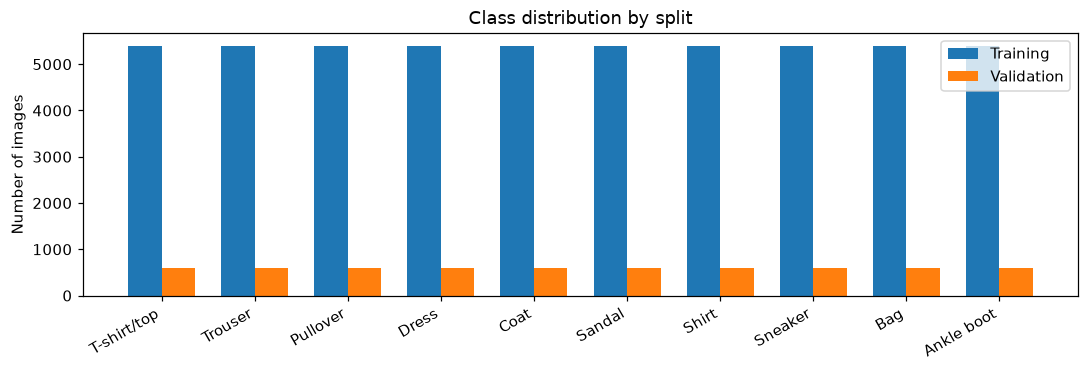

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
labels = np.arange(len(CLASS_NAMES))
ax.bar(labels - 0.18, train_counts, 0.36, label="Training")
ax.bar(labels + 0.18, validation_counts, 0.36, label="Validation")
ax.set_xticks(labels, CLASS_NAMES, rotation=30, ha="right")
ax.set(ylabel="Number of images", title="Class distribution by split")
ax.legend()
fig.tight_layout()
show_figure(fig)

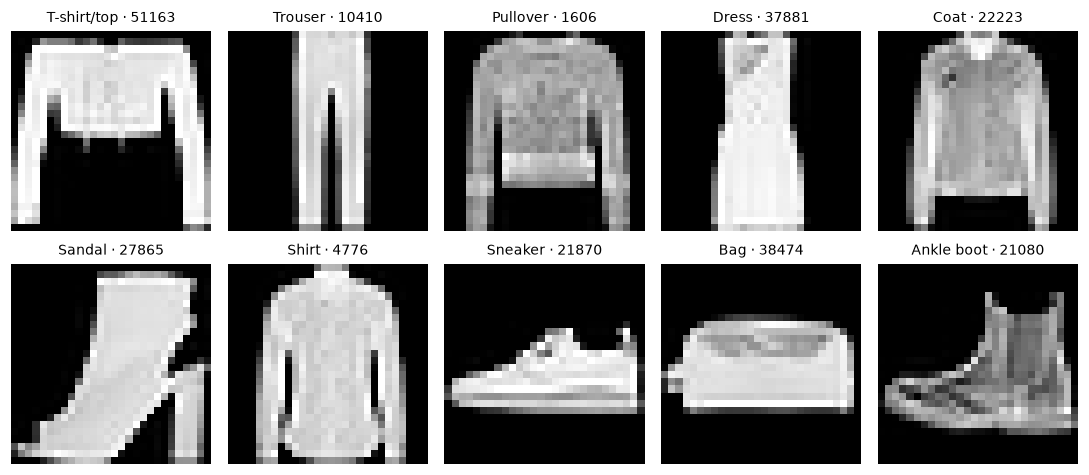

In [8]:
rng = np.random.default_rng(2026)
y = train_set.labels.numpy()
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for cls, ax in enumerate(axes.flat):
    index = int(rng.choice(train_set.indices[y[train_set.indices] == cls]))
    ax.imshow(train_set.images[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{CLASS_NAMES[cls]} · {index}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
show_figure(fig)

## Model architecture

Images become 28 row tokens or 49 non-overlapping 4×4 patches, read left to right and top to bottom.

In [9]:
seed_everything(SEEDS[0], DETERMINISTIC)
images = torch.stack([train_set[i][0] for i in range(4)])
model_shapes = []
with torch.inference_mode():
    for config in configs:
        model = build_model(config).eval()
        row = {
            "experiment": config.id,
            "parameters": parameter_count(model),
            "logits": list(model(images).shape),
        }
        if config.exercise == "E3":
            sequence = image_sequence(images, config.tokenizer, config.patch_size)
            row["sequence_shape"] = " × ".join(map(str, sequence.shape[1:]))
        model_shapes.append(row)
display(model_shapes)

[{'experiment': 'e1_mlp', 'parameters': 235146, 'logits': [4, 10]},
 {'experiment': 'e1_cnn', 'parameters': 421738, 'logits': [4, 10]},
 {'experiment': 'e3_lstm_rows',
  'parameters': 82186,
  'logits': [4, 10],
  'sequence_shape': '28 × 28'},
 {'experiment': 'e3_gru_rows',
  'parameters': 61962,
  'logits': [4, 10],
  'sequence_shape': '28 × 28'},
 {'experiment': 'e3_lstm_patches',
  'parameters': 76042,
  'logits': [4, 10],
  'sequence_shape': '49 × 16'},
 {'experiment': 'e3_gru_patches',
  'parameters': 57354,
  'logits': [4, 10],
  'sequence_shape': '49 × 16'}]

## Training and checkpoint selection

Checkpoints are selected by validation accuracy, with lower cross-entropy breaking ties.

In [10]:
run_environment = environment_info(device)
directories = {}
for config in configs:
    for seed in SEEDS:
        directory = OUTPUT_ROOT / config.id / f"seed_{seed}"
        status = verified_training_status(
            directory,
            config,
            seed,
            dataset,
            WORKERS,
            DETERMINISTIC,
            run_environment,
        )
        if status == "trained":
            print(f"Reusing completed run: {config.id}, seed={seed}", flush=True)
        else:
            if status == "incomplete" and not RESUME:
                raise RuntimeError(
                    f"Incomplete run: {directory}. Enable RESUME to continue."
                )
            directory = train(
                config,
                seed,
                DATA_ROOT,
                OUTPUT_ROOT,
                device_name=DEVICE,
                workers=WORKERS,
                resume=status == "incomplete",
                deterministic=DETERMINISTIC,
                download=DOWNLOAD,
            )
        directories[(config.id, seed)] = directory

Reusing completed run: e1_mlp, seed=42


Reusing completed run: e1_mlp, seed=43


Reusing completed run: e1_mlp, seed=44


Reusing completed run: e1_cnn, seed=42


Reusing completed run: e1_cnn, seed=43


Reusing completed run: e1_cnn, seed=44


... (368 outputs left out)

  27/30: CE=0.2459 | val=89.2333% | 0.6s


  28/30: CE=0.2446 | val=89.3500% | 0.6s


  29/30: CE=0.2435 | val=89.3333% | 0.6s


  30/30: CE=0.2429 | val=89.3167% | 0.6s


## Evaluation and error analysis

Accuracy, parameter count and training time summarize the comparison with the E1 baselines.

In [11]:
split = "test" if CONFIRM_TEST else "validation"
report_dir = (
    OUTPUT_ROOT
    / "notebook_analysis"
    / EXERCISE
    / ("seeds_" + "_".join(map(str, SEEDS)))
    / split
)
evaluations, results = {}, []
for (identifier, seed), directory in directories.items():
    result = evaluate_run(
        directory,
        DATA_ROOT,
        split=split,
        confirm_test=CONFIRM_TEST,
        device_name=DEVICE,
        workers=WORKERS,
        download=DOWNLOAD,
    )
    evaluations[(identifier, seed)] = result
    training = read_json(directory / "metrics.json")
    results.append(
        {
            "experiment": identifier,
            "seed": seed,
            "split": split,
            "best_epoch": result["best_epoch"],
            "accuracy": result["accuracy"],
            "macro_f1": result["macro_f1"],
            "cross_entropy": result["cross_entropy"],
            "n_parameters": training["n_parameters"],
            "median_train_seconds": training["median_train_seconds"],
            "total_train_seconds": training["total_train_seconds"],
            "inference_images_per_second": result["inference_images_per_second"],
            "signature": result["signature"],
            "model_sha256": result["model_sha256"],
        }
    )

/workspace/co5085/runs/notebooks/exercises/e1_mlp/seed_42: reuse existing test evaluation


/workspace/co5085/runs/notebooks/exercises/e1_mlp/seed_43: reuse existing test evaluation


/workspace/co5085/runs/notebooks/exercises/e1_mlp/seed_44: reuse existing test evaluation


/workspace/co5085/runs/notebooks/exercises/e1_cnn/seed_42: reuse existing test evaluation


/workspace/co5085/runs/notebooks/exercises/e1_cnn/seed_43: reuse existing test evaluation


/workspace/co5085/runs/notebooks/exercises/e1_cnn/seed_44: reuse existing test evaluation


... (8 outputs left out)

seed_44 test: accuracy=87.6200%, macro-F1=0.8759


seed_42 test: accuracy=87.7300%, macro-F1=0.8765


seed_43 test: accuracy=88.0900%, macro-F1=0.8804


seed_44 test: accuracy=88.1700%, macro-F1=0.8815


In [12]:
atomic_csv(report_dir / "results.csv", results)
atomic_json(
    report_dir / "protocol.json",
    {
        "notebook": f"{EXERCISE}.ipynb",
        "configurations": [config.to_dict() for config in configs],
        "seeds": list(SEEDS),
        "dataset": dataset,
        "device": str(device),
        "workers": WORKERS,
        "deterministic": DETERMINISTIC,
        "split": split,
        "confirm_test": CONFIRM_TEST,
    },
)
show_results(results)

| Configuration | Seed | Parameters | Accuracy mean ± SD (%) | Macro-F1 mean ± SD | Median training seconds/epoch |
| --- | --- | ---: | ---: | ---: | ---: |
| e1_mlp | 42, 43, 44 | 235,146 | 89.880 ± 0.144 | 0.899 ± 0.001 | 0.36 |
| e1_cnn | 42, 43, 44 | 421,738 | 92.687 ± 0.055 | 0.927 ± 0.000 | 0.47 |
| e3_lstm_rows | 42, 43, 44 | 82,186 | 89.577 ± 0.045 | 0.896 ± 0.000 | 0.37 |
| e3_gru_rows | 42, 43, 44 | 61,962 | 90.067 ± 0.169 | 0.901 ± 0.002 | 0.36 |
| e3_lstm_patches | 42, 43, 44 | 76,042 | 87.650 ± 0.376 | 0.876 ± 0.004 | 0.58 |
| e3_gru_patches | 42, 43, 44 | 57,354 | 87.997 ± 0.234 | 0.879 ± 0.003 | 0.55 |

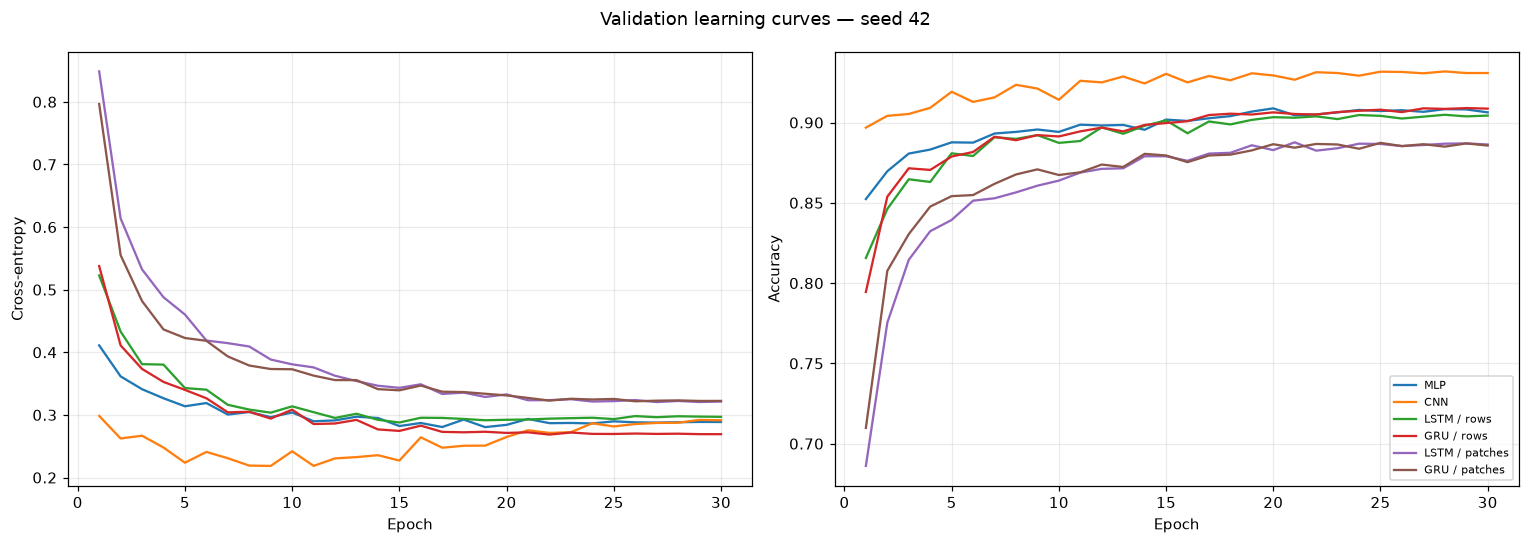

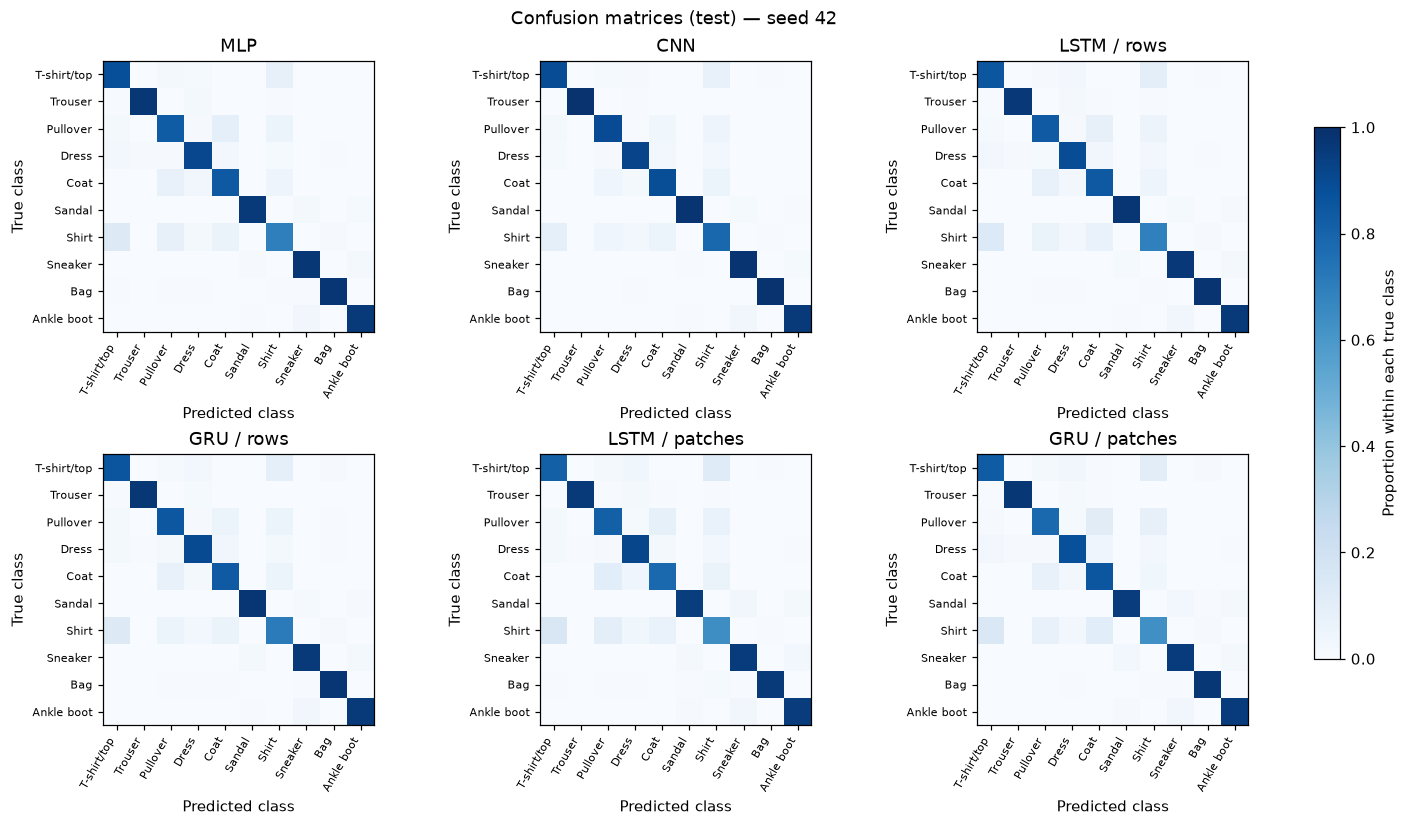

In [13]:
representative_seed = min(SEEDS)
show_comparison(configs, directories, evaluations, representative_seed, report_dir)

High-confidence errors: e1_mlp, seed=42


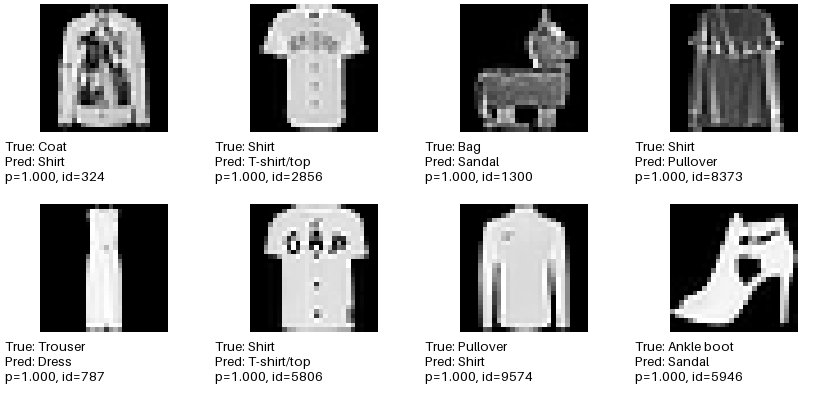

In [14]:
reference = configs[0].id
examples = (
    directories[(reference, representative_seed)] / "plots" / f"mistakes_{split}.png"
)
if examples.is_file():
    print(f"High-confidence errors: {reference}, seed={representative_seed}")
    display(Image(filename=str(examples), width=650))

## Sequence-order diagnostics

Original, reversed and fixed-permutation sequences are compared on 256 validation images, alongside gradients through intermediate recurrent states.

{'original': 0.90234375, 'reversed': 0.21484375, 'permuted': 0.44921875}
Gradients by sequence step: e3_lstm_rows, seed=42


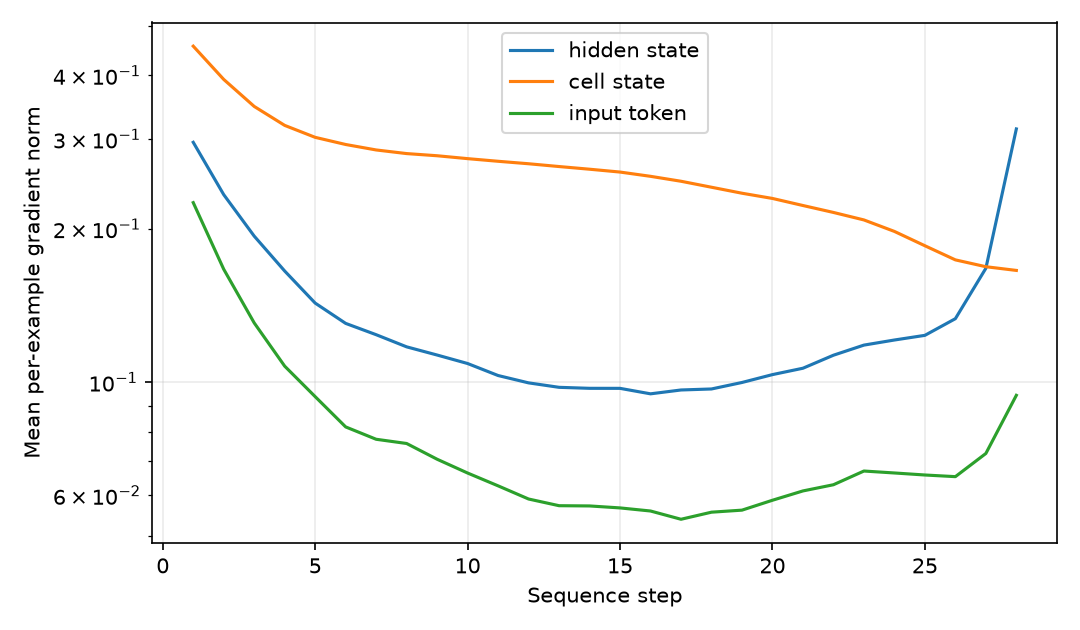

{'original': 0.89453125, 'reversed': 0.18359375, 'permuted': 0.46484375}


{'original': 0.89453125, 'reversed': 0.23046875, 'permuted': 0.421875}


{'original': 0.8984375, 'reversed': 0.1875, 'permuted': 0.421875}
Gradients by sequence step: e3_gru_rows, seed=42


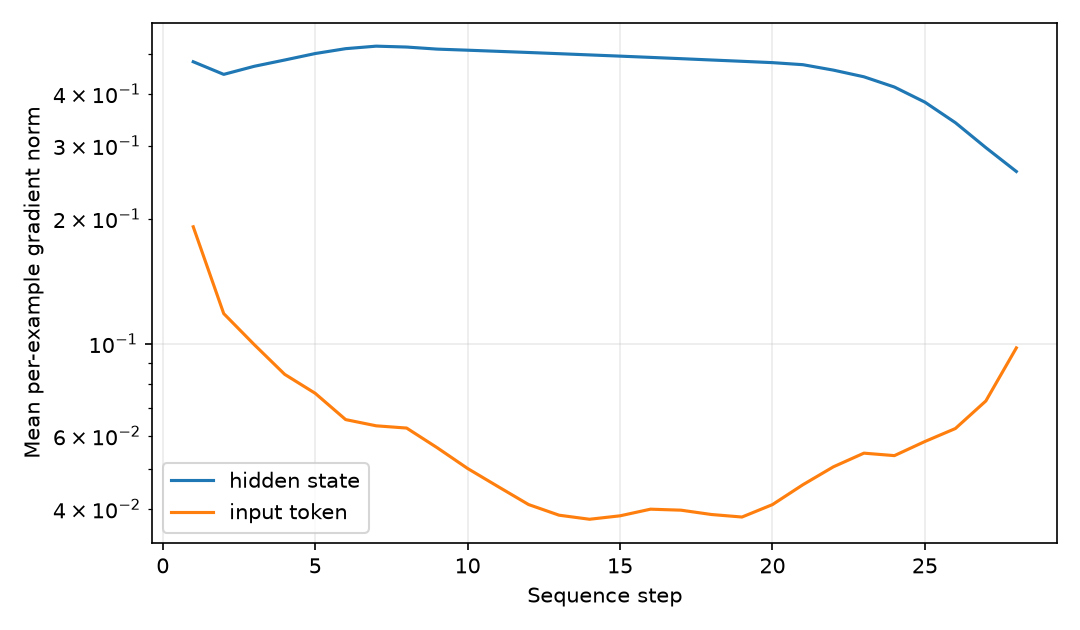

{'original': 0.89453125, 'reversed': 0.2109375, 'permuted': 0.49609375}


{'original': 0.90234375, 'reversed': 0.22265625, 'permuted': 0.515625}


{'original': 0.88671875, 'reversed': 0.1328125, 'permuted': 0.14453125}
Gradients by sequence step: e3_lstm_patches, seed=42


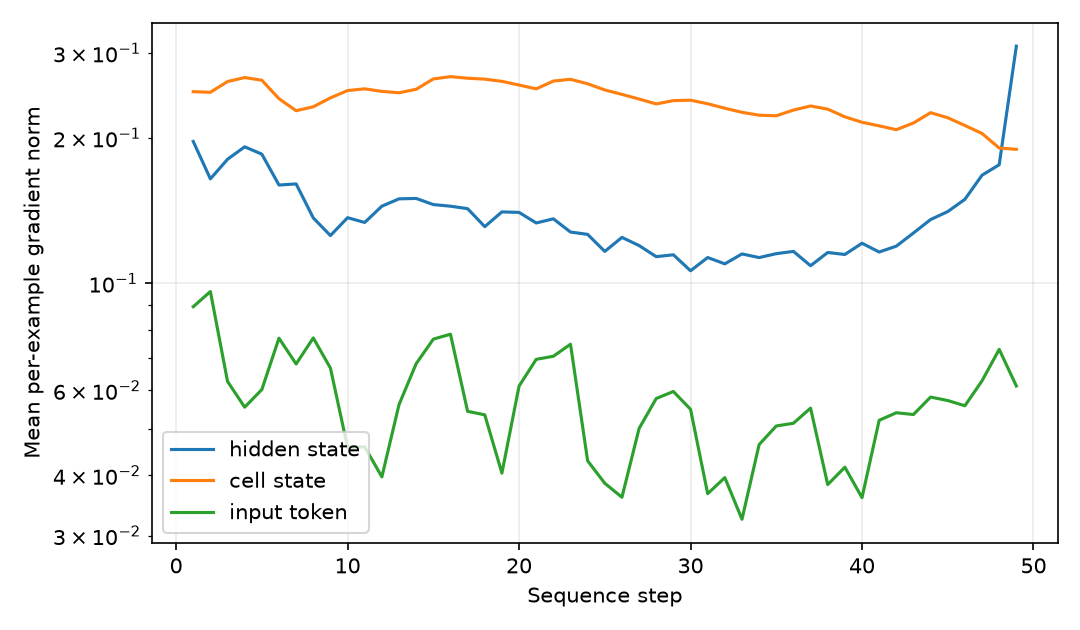

{'original': 0.87109375, 'reversed': 0.15625, 'permuted': 0.23046875}


{'original': 0.890625, 'reversed': 0.15234375, 'permuted': 0.14453125}


{'original': 0.8828125, 'reversed': 0.1484375, 'permuted': 0.15625}
Gradients by sequence step: e3_gru_patches, seed=42


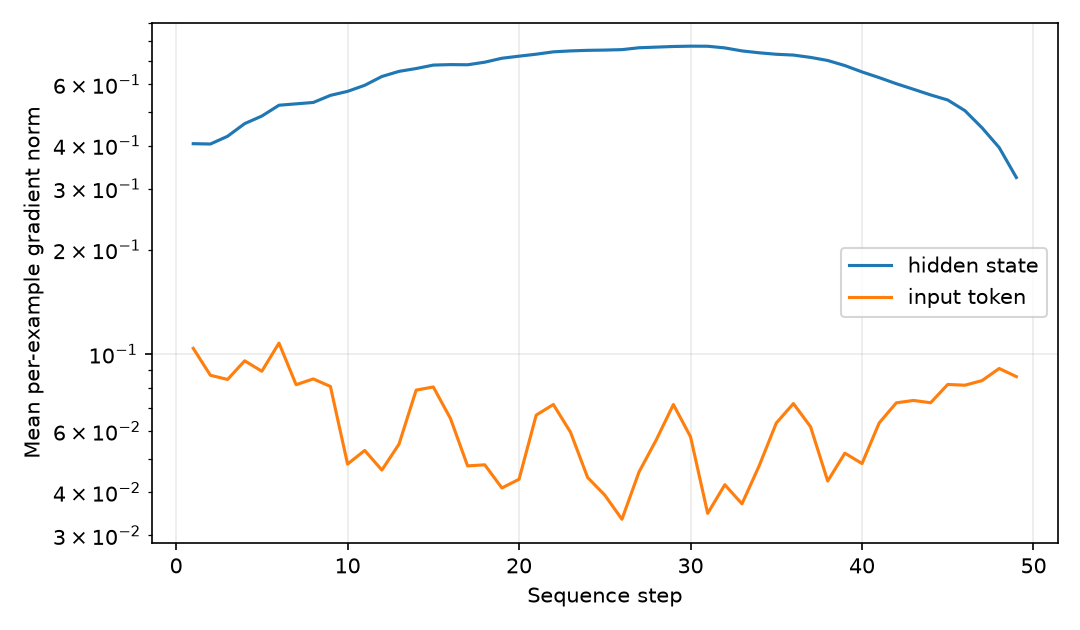

{'original': 0.88671875, 'reversed': 0.14453125, 'permuted': 0.15625}


{'original': 0.88671875, 'reversed': 0.1484375, 'permuted': 0.1875}


[{'experiment': 'e3_lstm_rows',
  'seed': 42,
  'n_samples': 256,
  'original': 0.90234375,
  'reversed': 0.21484375,
  'permuted': 0.44921875},
 {'experiment': 'e3_lstm_rows',
  'seed': 43,
  'n_samples': 256,
  'original': 0.89453125,
  'reversed': 0.18359375,
  'permuted': 0.46484375},
 {'experiment': 'e3_lstm_rows',
  'seed': 44,
  'n_samples': 256,
  'original': 0.89453125,
  'reversed': 0.23046875,
  'permuted': 0.421875},
 {'experiment': 'e3_gru_rows',
  'seed': 42,
  'n_samples': 256,
  'original': 0.8984375,
  'reversed': 0.1875,
  'permuted': 0.421875},
 {'experiment': 'e3_gru_rows',
  'seed': 43,
  'n_samples': 256,
  'original': 0.89453125,
  'reversed': 0.2109375,
  'permuted': 0.49609375},
 {'experiment': 'e3_gru_rows',
  'seed': 44,
  'n_samples': 256,
  'original': 0.90234375,
  'reversed': 0.22265625,
  'permuted': 0.515625},
 {'experiment': 'e3_lstm_patches',
  'seed': 42,
  'n_samples': 256,
  'original': 0.88671875,
  'reversed': 0.1328125,
  'permuted': 0.14453125}

In [15]:
from E3.diagnose import diagnose

targets = {config.id for config in configs if config.exercise == EXERCISE}
diagnostic_rows = []
for (identifier, seed), directory in directories.items():
    if identifier not in targets:
        continue
    diagnose(directory, DATA_ROOT, DEVICE, max_samples=256, batch_size=32)
    diagnostic = read_json(directory / "diagnostics" / "summary.json")
    diagnostic_rows.append(
        {
            "experiment": identifier,
            "seed": seed,
            "n_samples": diagnostic["n_samples"],
            **diagnostic["accuracy"],
        }
    )
    if seed == representative_seed:
        print(f"Gradients by sequence step: {identifier}, seed={seed}")
        display(
            Image(
                filename=str(directory / "diagnostics" / "temporal_gradients.png"),
                width=650,
            )
        )
if diagnostic_rows:
    atomic_csv(report_dir / "sequence_order.csv", diagnostic_rows)
    display(diagnostic_rows)

## Comparison limits

Order changes alter the input distribution, while sequences of 28 or 49 steps limit conclusions about long-term memory.